In [1]:
# Ячейка 1. Метод Канторовича для замкнутой системы уровня L (здесь L = 3): решатель.
# Обозначения как в документе: P = Σ h_k(x) g_k(t),  V = Σ p_k(x) r_k(s;t1),  w(t1,s) = Σ ⟨φ,p_j⟩ r_j(τ−s; t1−τ+s).
# time_step  — ОДУ по времени (уравнения 8.4): Σ⟨h_i,h_j⟩ ġ_j = −D Σ⟨h_i',h_j'⟩ g_j + γ Σ⟨h_i,p_j'⟩ r_j(τ,t−τ)  и такое же для r_k;
#              решаются шагом  g(t+dt) = e^{A dt} g(t) + A^{-1}(e^{A dt}−1) b,  A = −D M^{-1} S,  b = γ M^{-1} B·(источник).
#              Попутно накапливаются интегралы по времени ⟨g_i,g_j⟩, ⟨g_i,ġ_j⟩, ⟨g_i, r_j(τ,t−τ)⟩, … (словарь I) для шага по x.
# x_step     — ОДУ по x (уравнения 8.3): Σ(⟨g_i,ġ_j⟩+g_i(τ)g_j(τ)) h_j − D Σ⟨g_i,g_j⟩ h_j'' − γ Σ⟨g_i,r_j(τ,t−τ)⟩ p_j' = g_i(τ) P_ex
#              и такое же для p_j; h'' → матрица D2, p' → D1; краевая задача h(±L)=p(±L)=0 решается как одна линейная система.
# solve      — чередование time_step / x_step до сходимости P(x,t).
import numpy as np
import scipy.sparse as sp
import scipy.sparse.linalg as spl
from scipy.linalg import expm, qr

# ---------------- параметры ----------------
D, gam, T, dt = 1.0, 1.0, 12.0, 0.02
phi_fun = np.tanh
X = np.linspace(-15.0, 15.0, 601)          # сетка по x, на концах f = 0
dx = X[1] - X[0]
PHI = phi_fun(X)


def setup(phi, T_=12.0, Lx=15.0, N=601, dt_=0.02):
    """Задать силу φ, горизонт T и сетку по x (вызывать перед solve)."""
    global phi_fun, X, dx, PHI, T, dt
    phi_fun, T, dt = phi, T_, dt_
    X = np.linspace(-Lx, Lx, N); dx = X[1] - X[0]; PHI = phi_fun(X)


def gauss(t):
    """Точное P(x,t) на 0 <= t <= τ (сноса нет, так как φ(0)=0)."""
    t = max(t, dt / 2)
    return np.exp(-X**2 / (4 * D * t)) / np.sqrt(4 * np.pi * D * t)


def ip(a, b):
    """<a, b> — интеграл произведения по x (столбцы — функции)."""
    return dx * a.T @ b


def orthonormalize(f):
    q, _ = qr(np.sqrt(dx) * f, mode='economic')
    return q / np.sqrt(dx)


def start_basis(rank, parity):
    """Начальные функции от x: функции Эрмита нужной чётности."""
    z = X / (1.5 * np.sqrt(2))
    H = [np.ones_like(z), 2 * z]
    for n in range(1, 2 * rank + 1):
        H.append(2 * z * H[n] - 2 * n * H[n - 1])
    return orthonormalize(np.array([H[2 * k + parity] * np.exp(-z**2 / 2) for k in range(rank)]).T)


# ---------------- шаг по времени ----------------
def time_step(f, level, tau):
    """Варьирование по функциям времени: при известных f[m](x) — задачи Коши по возрасту.
    Возвращает g_k(t) и интегралы по времени, нужные шагу по x."""
    top = level - 2                                   # номер последней функции (V, Z или Y)
    K, n, R = int(round(tau / dt)), int(round(T / dt)), f[0].shape[1]
    fx = [np.gradient(v, dx, axis=0) for v in f]      # f'(x)
    M = [ip(v, v) for v in f]                         # <f_i, f_j>
    S = [ip(v, v) for v in fx]                        # <f_i', f_j'>
    B = [ip(f[m], fx[m + 1]) for m in range(top)] + [ip(f[top], fx[0])]   # <f_i, ψ_j'>
    Cr = [None] + [np.linalg.solve(M[m], ip(f[m], PHI[:, None] * f[m - 1])) for m in range(1, top + 1)]
    phv = dx * PHI @ f[top]                           # <φ, f_top,j>
    A = [-D * np.linalg.solve(M[m], S[m]) for m in range(top + 1)]
    Bs = [gam * np.linalg.solve(M[m], B[m]) for m in range(top + 1)]
    E = [expm(A[m] * dt) for m in range(top + 1)]                       # точный шаг без источника
    Fs = [np.linalg.solve(A[m], E[m] - np.eye(R)) @ Bs[m] for m in range(top + 1)]   # вклад источника

    # индексы для момента в последнем уравнении: M(t_m,...,t_1, t-τ) взят из прошлого
    ages = np.indices((K + 1,) * top)
    ok = np.ones((K + 1,) * top, bool)
    for j in range(top - 1):
        ok &= ages[j] <= ages[j + 1]
    lag = ages[0]
    where = (lag,) + tuple(ages[j] - lag for j in range(1, top)) + (K - lag,)
    where = tuple(np.clip(w, 0, K) for w in where)

    C = [None] + [np.zeros((K + 1,) * m + (R,)) for m in range(1, top + 1)]
    Mom = np.zeros((K + 1,) + (K + 1,) * top)         # Mom[лаг][возрасты] — моменты за последние τ
    Z = lambda: [np.zeros((R, R)) for _ in range(top + 1)]
    I = dict(cc=Z(), cdc=Z(), c0c0=Z(), csig=Z(), c0prev=Z(), pex=np.zeros((R, len(X))))
    g_all = np.zeros((n + 1, R)); g = None

    for i in range(n + 1):
        t = i * dt
        if i == K:                                    # начальное условие для g_k(τ)
            g = np.linalg.solve(M[0], ip(f[0], gauss(tau)))
            I['g_tau'] = g.copy()
        if i >= K:
            g_all[i] = g
        # рождение функций с возрастом 0: F_m(x,0;...) = φ(x) F_{m-1}(x,...)
        C[1][0] = Cr[1] @ g if i >= K else np.linalg.solve(M[1], ip(f[1], PHI * gauss(t)))
        I['c0c0'][1] += dt * np.outer(C[1][0], C[1][0])
        if i >= K: I['c0prev'][1] += dt * np.outer(C[1][0], g)
        else:      I['pex'] += dt * np.outer(C[1][0], gauss(t))
        for m in range(2, top + 1):
            C[m][0] = C[m - 1] @ Cr[m].T
            new, old = C[m][0].reshape(-1, R), C[m - 1].reshape(-1, R)
            I['c0c0'][m] += dt**m * new.T @ new
            I['c0prev'][m] += dt**m * new.T @ old
        Mom = np.roll(Mom, 1, axis=0); Mom[0] = C[top] @ phv
        if i == n:
            break
        # источники: следующая функция с новой ранней точкой t-τ (возраст K) или момент · P
        sig = [C[m + 1][..., K, :] for m in range(1, top)]
        mom = np.where(ok, Mom[where], 0.0)
        sig.append(mom[..., None] * g if i >= K else np.zeros_like(C[top]))
        for m in range(1, top + 1):
            c, s, w = C[m].reshape(-1, R), sig[m - 1].reshape(-1, R), dt**(m + 1)
            I['cc'][m] += w * c.T @ c
            I['cdc'][m] += w * c.T @ (c @ A[m].T + s @ Bs[m].T)
            I['csig'][m] += w * c.T @ s
        if i >= K:                                    # уравнение для P: источник V(x,τ;t-τ)
            s = C[1][K]
            I['cc'][0] += dt * np.outer(g, g)
            I['cdc'][0] += dt * np.outer(g, A[0] @ g + Bs[0] @ s)
            I['csig'][0] += dt * np.outer(g, s)
            g = E[0] @ g + Fs[0] @ s
        for m in range(1, top + 1):                   # шаг по возрасту и сдвиг возрастов
            Cn = C[m] @ E[m].T + sig[m - 1] @ Fs[m].T
            C[m] = np.zeros_like(Cn)
            C[m][(slice(1, None),) * m] = Cn[(slice(None, -1),) * m]
    return g_all, I


# ---------------- шаг по x ----------------
def x_step(I, level, tau, R):
    """Варьирование по функциям от x: одна краевая задача для всех f[m](x), f(±15) = 0."""
    top = level - 2
    m = len(X) - 2
    D2 = sp.diags([1., -2., 1.], [-1, 0, 1], (m, m)) / dx**2
    D1 = sp.diags([-1., 1.], [-1, 1], (m, m)) / (2 * dx)
    Id, Phi = sp.eye(m), sp.diags(PHI[1:-1])
    kr = lambda a, op: sp.kron(sp.csr_matrix(a), op)
    blocks = [[None] * (top + 1) for _ in range(top + 1)]
    rhs = []
    for k in range(top + 1):
        c0c0 = np.outer(I['g_tau'], I['g_tau']) if k == 0 else I['c0c0'][k]
        blocks[k][k] = kr(I['cdc'][k] + c0c0, Id) - D * kr(I['cc'][k], D2)
        nxt = k + 1 if k < top else 0
        add = -gam * kr(I['csig'][k], D1)
        blocks[k][nxt] = add if blocks[k][nxt] is None else blocks[k][nxt] + add
        if k >= 1:
            add = -kr(I['c0prev'][k], Phi)
            blocks[k][k - 1] = add if blocks[k][k - 1] is None else blocks[k][k - 1] + add
        if k == 0:   r = np.outer(I['g_tau'], gauss(tau)[1:-1])
        elif k == 1: r = I['pex'][:, 1:-1] * PHI[None, 1:-1]
        else:        r = np.zeros((R, m))
        rhs.append(r.ravel())
    U = spl.spsolve(sp.bmat(blocks, format='csc'), np.concatenate(rhs)).reshape(top + 1, R, m)
    f = []
    for k in range(top + 1):
        fk = np.zeros((len(X), R)); fk[1:-1] = U[k].T
        f.append(orthonormalize(fk))
    return f


# ---------------- итерации ----------------
def density(f, g_all, tau):
    K = int(round(tau / dt))
    return np.array([f[0] @ g_all[i] if i >= K else gauss(i * dt) for i in range(len(g_all))])


def variance(P):
    m0 = P.sum(1) * dx
    mu = P @ X * dx / m0
    return P @ X**2 * dx / m0 - mu**2


def solve(level, tau, rank, iters=20, tol=1e-5, verbose=True):
    f = [start_basis(rank, m % 2) for m in range(level - 1)]   # P, Z — чётные; V, Y — нечётные
    g_all, I = time_step(f, level, tau)
    P = density(f, g_all, tau)
    for it in range(1, iters + 1):
        f = x_step(I, level, tau, rank)
        g_all, I = time_step(f, level, tau)
        Pn = density(f, g_all, tau)
        change = np.linalg.norm(Pn - P) / np.linalg.norm(Pn)
        P = Pn
        if verbose: print(f'уровень {level}, ранг {rank}, итерация {it}: изменение {change:.1e}, Var x(T) = {variance(P)[-1]:.4f}')
        if change < tol or not np.isfinite(change):
            break
    return P


# ---------------- Монте-Карло для сравнения ----------------
def monte_carlo(tau, paths=100_000, h=1e-3, seed=1):
    rng = np.random.default_rng(seed)
    K, n = int(round(tau / h)), int(round(T / h))
    hist = np.zeros((K + 1, paths))                   # x за последние τ (кольцевой буфер)
    x = np.zeros(paths)
    for i in range(n):
        x_delay = hist[(i - K) % (K + 1)] if i >= K else 0.0
        hist[i % (K + 1)] = x
        x = x - gam * phi_fun(x_delay) * h + np.sqrt(2 * D * h) * rng.standard_normal(paths)
    return x.var()


ранг 1: Var x(6) = 2.2534
ранг 2: Var x(6) = 2.0892
ранг 3: Var x(6) = 1.8446
ранг 4: Var x(6) = 1.8392


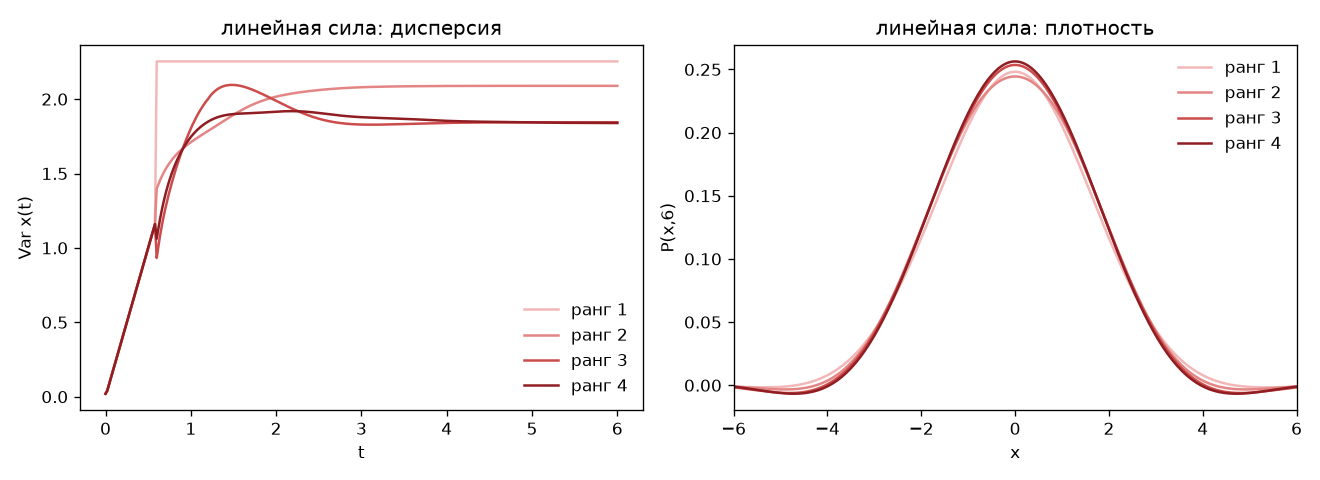

In [2]:
# Ячейка 2. Метод Канторовича, уровень 3, ЛИНЕЙНАЯ сила φ(x) = x
# Модель: dx = -γ x(t-τ) dt + sqrt(2D) dW,  x(t<=0) = 0,  γ = D = 1, τ = 0.6.
# Система уровня 3 для линейной силы неустойчива по t (хвосты плотности), поэтому горизонт T = 6.
import matplotlib.pyplot as plt
tau, T = 0.6, 6.0
setup(lambda z: z, T_=T)
lin = {}
for rank in (1, 2, 3, 4):
    P = solve(level=3, tau=tau, rank=rank, iters=20, verbose=False)
    lin[rank] = dict(P=P, var=variance(P))
    print(f'ранг {rank}: Var x({T:g}) = {lin[rank]["var"][-1]:.4f}')
t_lin = np.arange(len(lin[1]['var'])) * dt
x_lin = X.copy()
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
for rank, c in zip(lin, ['#f2b8b8', '#e48585', '#cc4b4b', '#8f1d22']):
    ax[0].plot(t_lin, lin[rank]['var'], color=c, label=f'ранг {rank}')
    ax[1].plot(x_lin, lin[rank]['P'][-1], color=c, label=f'ранг {rank}')
ax[0].set(xlabel='t', ylabel='Var x(t)', title='линейная сила: дисперсия'); ax[0].legend(frameon=False)
ax[1].set(xlim=(-6, 6), xlabel='x', ylabel=f'P(x,{T:g})', title='линейная сила: плотность'); ax[1].legend(frameon=False)
plt.tight_layout(); plt.show()


Монте-Карло: Var x(6) = 1.8932;   точно: 1.8960
ранг 1: 2.2534  (+18.8% от точного)
ранг 2: 2.0892  (+10.2% от точного)
ранг 3: 1.8446  (-2.7% от точного)
ранг 4: 1.8392  (-3.0% от точного)


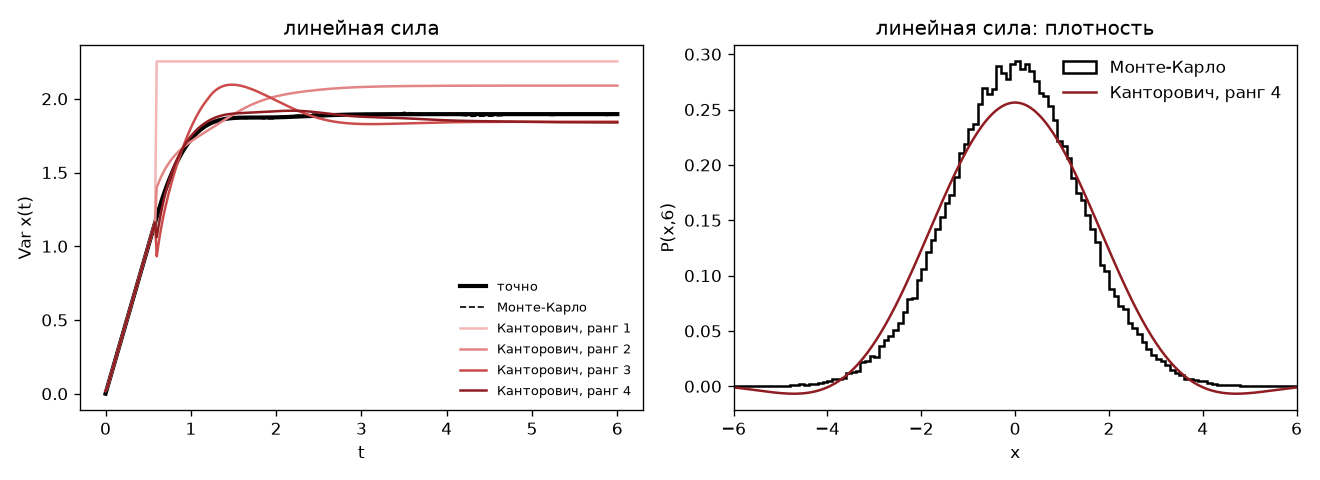

In [3]:
# Ячейка 3. Монте-Карло для ЛИНЕЙНОЙ силы + сравнение с ячейкой 2
# Для линейной силы дисперсия известна точно: Var(t) = 2D ∫_0^t Λ(s)^2 ds,  Λ' = -γ Λ(t-τ), Λ(0)=1.
def monte_carlo(phi, tau, T, paths=100_000, h=1e-3, rec=0.05, seed=1, D=1.0, gam=1.0):
    rng = np.random.default_rng(seed); K, n, rn = int(round(tau / h)), int(round(T / h)), int(round(rec / h))
    hist = np.zeros((K + 1, paths)); x = np.zeros(paths); t, var = [0.0], [0.0]
    for i in range(n):
        xd = hist[(i - K) % (K + 1)] if i >= K else 0.0
        hist[i % (K + 1)] = x
        x = x - gam * phi(xd) * h + np.sqrt(2 * D * h) * rng.standard_normal(paths)
        if (i + 1) % rn == 0: t.append((i + 1) * h); var.append(x.var())
    return np.array(t), np.array(var), x

def exact_linear_var(tau, T, dt=2e-4):
    n, K = int(round(T / dt)), int(round(tau / dt)); Lam = np.zeros(n + 1); Lam[0] = 1
    for i in range(n): Lam[i + 1] = Lam[i] - dt * (Lam[i - K] if i >= K else 0)
    return np.arange(n + 1) * dt, 2 * np.cumsum(Lam**2) * dt

t_mc, var_mc, x_end = monte_carlo(lambda z: z, tau, T)
t_ex, var_ex = exact_linear_var(tau, T)
print(f'Монте-Карло: Var x({T:g}) = {var_mc[-1]:.4f};   точно: {var_ex[-1]:.4f}')
for rank in lin: print(f'ранг {rank}: {lin[rank]["var"][-1]:.4f}  ({100*(lin[rank]["var"][-1]/var_ex[-1]-1):+.1f}% от точного)')
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
ax[0].plot(t_ex, var_ex, 'k', lw=2.5, label='точно'); ax[0].plot(t_mc, var_mc, 'k--', lw=1, label='Монте-Карло')
for rank, c in zip(lin, ['#f2b8b8', '#e48585', '#cc4b4b', '#8f1d22']): ax[0].plot(t_lin, lin[rank]['var'], color=c, label=f'Канторович, ранг {rank}')
ax[0].set(xlabel='t', ylabel='Var x(t)', title='линейная сила'); ax[0].legend(frameon=False, fontsize=8)
ax[1].hist(x_end, bins=120, range=(-6, 6), density=True, histtype='step', color='k', lw=1.5, label='Монте-Карло')
ax[1].plot(x_lin, lin[max(lin)]['P'][-1], color='#8f1d22', label=f'Канторович, ранг {max(lin)}')
ax[1].set(xlim=(-6, 6), xlabel='x', ylabel=f'P(x,{T:g})', title='линейная сила: плотность'); ax[1].legend(frameon=False)
plt.tight_layout(); plt.show()


ранг 1: Var x(12) = 3.5595
ранг 2: Var x(12) = 3.2054
ранг 3: Var x(12) = 3.1852
ранг 4: Var x(12) = 3.2067
ранг 5: Var x(12) = 3.1912
ранг 6: Var x(12) = 3.1758


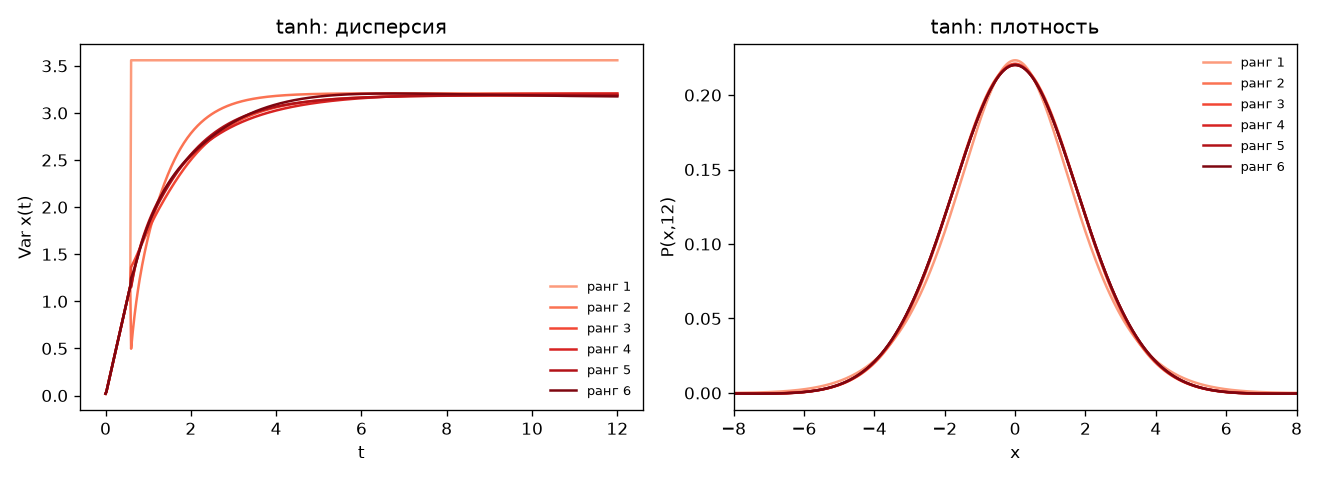

In [4]:
# Ячейка 4. Метод Канторовича, уровень 3, НЕЛИНЕЙНАЯ сила φ(x) = tanh x
# Модель: dx = -γ tanh(x(t-τ)) dt + sqrt(2D) dW,  x(t<=0) = 0,  γ = D = 1, τ = 0.6, T = 12.
tau, T = 0.6, 12.0
setup(np.tanh, T_=T)
nl = {}
for rank in (1, 2, 3, 4, 5, 6):
    P = solve(level=3, tau=tau, rank=rank, iters=20, verbose=False)
    nl[rank] = dict(P=P, var=variance(P))
    print(f'ранг {rank}: Var x({T:g}) = {nl[rank]["var"][-1]:.4f}')
t_nl = np.arange(len(nl[1]['var'])) * dt
x_nl = X.copy()
cols = plt.cm.Reds(np.linspace(0.35, 0.95, len(nl)))
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
for (rank, d), c in zip(nl.items(), cols):
    ax[0].plot(t_nl, d['var'], color=c, label=f'ранг {rank}'); ax[1].plot(x_nl, d['P'][-1], color=c, label=f'ранг {rank}')
ax[0].set(xlabel='t', ylabel='Var x(t)', title='tanh: дисперсия'); ax[0].legend(frameon=False, fontsize=8)
ax[1].set(xlim=(-8, 8), xlabel='x', ylabel=f'P(x,{T:g})', title='tanh: плотность'); ax[1].legend(frameon=False, fontsize=8)
plt.tight_layout(); plt.show()


Монте-Карло: Var x(12) = 3.4692
ранг 1: 3.5595  (+2.6% от Монте-Карло)
ранг 2: 3.2054  (-7.6% от Монте-Карло)
ранг 3: 3.1852  (-8.2% от Монте-Карло)
ранг 4: 3.2067  (-7.6% от Монте-Карло)
ранг 5: 3.1912  (-8.0% от Монте-Карло)
ранг 6: 3.1758  (-8.5% от Монте-Карло)


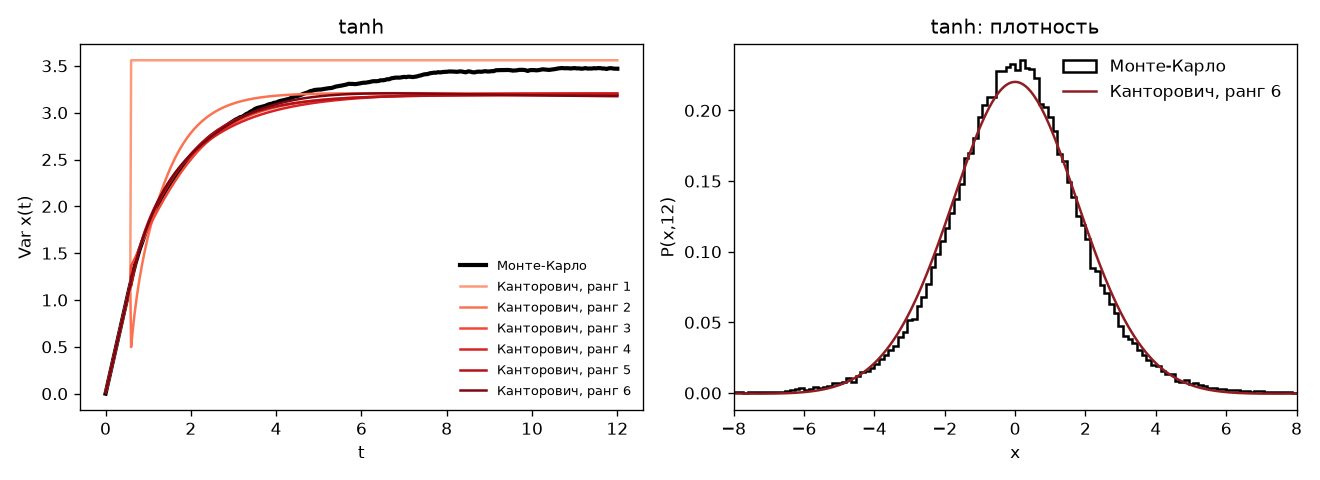

In [5]:
# Ячейка 5. Монте-Карло для НЕЛИНЕЙНОЙ силы + сравнение с ячейкой 4
t_mc, var_mc, x_end = monte_carlo(np.tanh, tau, T)
print(f'Монте-Карло: Var x({T:g}) = {var_mc[-1]:.4f}')
for rank in nl: print(f'ранг {rank}: {nl[rank]["var"][-1]:.4f}  ({100*(nl[rank]["var"][-1]/var_mc[-1]-1):+.1f}% от Монте-Карло)')
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
ax[0].plot(t_mc, var_mc, 'k', lw=2.5, label='Монте-Карло')
for (rank, d), c in zip(nl.items(), cols): ax[0].plot(t_nl, d['var'], color=c, label=f'Канторович, ранг {rank}')
ax[0].set(xlabel='t', ylabel='Var x(t)', title='tanh'); ax[0].legend(frameon=False, fontsize=8)
ax[1].hist(x_end, bins=120, range=(-8, 8), density=True, histtype='step', color='k', lw=1.5, label='Монте-Карло')
ax[1].plot(x_nl, nl[max(nl)]['P'][-1], color='#8f1d22', label=f'Канторович, ранг {max(nl)}')
ax[1].set(xlim=(-8, 8), xlabel='x', ylabel=f'P(x,{T:g})', title='tanh: плотность'); ax[1].legend(frameon=False)
plt.tight_layout(); plt.show()
